<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 2, Depth Anything casero: DINOv2 y DPT**


En el notebook anterior usamos una red convolucional (ResNet-18 + U-Net). Ahora armamos la misma idea que usan Depth Anything V2 y V3 pero de manera casera:

- **Encoder:** DINOv2-small, un Vision Transformer preentrenado con auto-supervisión. Corta la imagen en parches de 14 × 14 y cada parche "consulta" a todos los demás con atención.
- **Decoder tipo DPT:** toma los tokens de cuatro capas del ViT, los vuelve a acomodar como imágenes de distinto tamaño y los fusiona de lo grueso a lo fino.

Datos, pérdida y evaluación son los mismos que en el notebook anterior, así se pueden comparar las dos arquitecturas

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import h5py
import matplotlib.pyplot as plt
from transformers import Dinov2Model

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("usando:", dispositivo)

usando: cuda


**1. Datos**

Primero se intenta una copia en Hugging Face y, si falla, el servidor de NYU.

El ViT trabaja con parches de 14 × 14, así que el tamaño de la imagen tiene que ser múltiplo de 14. Usamos 252 × 196: quedan 18 × 14 = 252 parches.

In [ ]:
import os, glob, shutil

ARCHIVO = "nyu_depth_v2_labeled.mat"
URL_HF = "https://huggingface.co/datasets/kronecker0122/nyuv2/resolve/main/nyuv2.tar.zst.part-00"
URL_NYU = "http://horatio.cs.nyu.edu/mit/silberman/nyu_depth_v2/nyu_depth_v2_labeled.mat"

if not os.path.exists(ARCHIVO):
    # 1. copia en Hugging Face: un .tar.zst con el .mat adentro; se descomprime mientras baja
    !wget -q --show-progress -O - {URL_HF} | tar --zstd -xf -
    encontrados = glob.glob("**/" + ARCHIVO, recursive=True)
    if encontrados:
        shutil.move(encontrados[0], ARCHIVO)

if not os.path.exists(ARCHIVO) or os.path.getsize(ARCHIVO) < 2e9:
    # 2. si falló, servidor original de NYU (más lento)
    !wget -q --show-progress -O {ARCHIVO} {URL_NYU}

print(f"{ARCHIVO}: {os.path.getsize(ARCHIVO) / 1e9:.2f} GB")

tar (grandchild): zstd: Cannot exec: No such file or directory
tar (grandchild): Error is not recoverable: exiting now
-                     0%[                    ]   1.35K  1.12KB/s               tar: Child died with signal 13
tar: Error is not recoverable: exiting now
-                     0%[                    ]  46.05K  38.4KB/s    in 1.2s    
nyu_depth_v2_labele 100%[===================>]   2.77G  47.7MB/s    in 60s     
nyu_depth_v2_labeled.mat: 2.97 GB


In [ ]:
ALTO, ANCHO = 196, 252
PARCHE = 14

# leemos de a 100 fotos para no llenar la memoria
lista_ell, lista_z = [], []
with h5py.File("nyu_depth_v2_labeled.mat", "r") as f:
    for i in range(0, len(f["images"]), 100):
        ell = torch.from_numpy(f["images"][i:i + 100]).permute(0, 1, 3, 2).float() / 255   # (100, 3, 480, 640)
        z = torch.from_numpy(f["depths"][i:i + 100]).permute(0, 2, 1)[:, None]            # (100, 1, 480, 640)
        lista_ell.append(F.interpolate(ell, size=(ALTO, ANCHO), mode="bilinear", antialias=True))
        lista_z.append(F.interpolate(z, size=(ALTO, ANCHO), mode="nearest"))

imagenes, profundidades = torch.cat(lista_ell), torch.cat(lista_z)

# misma separación que en el notebook CNN: uno de cada seis bloques de 25 fotos para prueba
indices = np.arange(len(imagenes))
es_prueba = (indices // 25) % 6 == 0
ell_entren, z_entren = imagenes[~es_prueba], profundidades[~es_prueba]
ell_prueba, z_prueba = imagenes[es_prueba], profundidades[es_prueba]
print(f"entrenamiento: {len(ell_entren)} fotos   prueba: {len(ell_prueba)} fotos")

entrenamiento: 1199 fotos   prueba: 250 fotos


**2. Encoder: DINOv2**

* DINOv2-small tiene 12 capas de Transformer y representa cada parche con un vector de 384 números
* le pedimos todas las capas intermedias (output_hidden_states=True) porque el decoder usa cuatro de ellas: las primeras guardan detalle fino y las últimas el significado de la escena

In [ ]:
dino = Dinov2Model.from_pretrained("facebook/dinov2-small", attn_implementation="eager")   # "eager" permite ver la atención
CAPAS = [3, 6, 9, 12] # mismas capas que usa Depth Anything en su versión small
C = dino.config.hidden_size # 384

In [ ]:
with torch.no_grad():
    salida = dino(pixel_values=torch.zeros(1, 3, ALTO, ANCHO), output_hidden_states=True)
print("capas disponibles:", len(salida.hidden_states))
print("tokens por imagen:", salida.hidden_states[-1].shape[1], "= 1 token CLS +", (ALTO // PARCHE) * (ANCHO // PARCHE), "parches")

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

capas disponibles: 13
tokens por imagen: 253 = 1 token CLS + 252 parches


**3. El decoder DPT**

Tres pasos:

1. **Reacomodar:** los tokens de cada capa vuelven a formar una imagen de 14 × 18. Después se llevan a cuatro tamaños distintos (×4, ×2, ×1 y ×½), como si fueran las etapas de una CNN
2. **Fusionar:** se empieza por el mapa más pequeño, se agranda y se suma con el siguiente, pasando por bloques residuales, así lo global (qué hay en la escena) se combina con el detalle (dónde están los bordes)
3. **Cabeza:** dos convoluciones que dan un valor por píxel: log ẑ

In [ ]:
FEAT = 64 # canales del decoder

# convierte los tokens de cuatro capas del Transformer, que tienen todos el mismo tamaño (14 × 18),
# en cuatro mapas de distinto tamaño (56 × 72, 28 × 36, 14 × 18 y 7 × 9), todos con 64 canales
reacomodar = nn.ModuleList([
    nn.Sequential(nn.Conv2d(C, 48, 1),
                  nn.ConvTranspose2d(48, 48, 4, stride=4),
                  nn.Conv2d(48, FEAT, 3, padding=1)),

    nn.Sequential(nn.Conv2d(C, 96, 1),
                  nn.ConvTranspose2d(96, 96, 2, stride=2),
                  nn.Conv2d(96, FEAT, 3, padding=1)),

    nn.Sequential(nn.Conv2d(C, 192, 1),
                  nn.Conv2d(192, FEAT, 3, padding=1)),

    nn.Sequential(nn.Conv2d(C, 384, 1),
                  nn.Conv2d(384, 384, 3, stride=2, padding=1),
                  nn.Conv2d(384, FEAT, 3, padding=1)),
])

# crea un bloque de dos convoluciones que le suma una corrección a su entrada en lugar de reemplazarla
def residual():
    return nn.Sequential(nn.ReLU(),
                         nn.Conv2d(FEAT, FEAT, 3, padding=1),
                         nn.ReLU(),
                         nn.Conv2d(FEAT, FEAT, 3, padding=1))

fusion = nn.ModuleList([nn.ModuleDict({"entrada": residual(), "salida": residual(), "proy": nn.Conv2d(FEAT, FEAT, 1)})
                        for _ in range(4)])

# reduce los 64 canales a uno solo para dar un valor por píxel: el logaritmo de la profundidad
cabeza = nn.Sequential(nn.Conv2d(FEAT, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 1, 1))

red = nn.ModuleDict({"dino": dino, "reacomodar": reacomodar, "fusion": fusion, "cabeza": cabeza}).to(dispositivo)
n_enc = sum(p.numel() for p in red["dino"].parameters())
n_total = sum(p.numel() for p in red.parameters())
print(f"parámetros: encoder {n_enc / 1e6:.1f} M   decoder {(n_total - n_enc) / 1e6:.1f} M")

parámetros: encoder 22.1 M   decoder 2.7 M


In [ ]:
MEDIA = torch.tensor([0.485, 0.456, 0.406], device=dispositivo).view(1, 3, 1, 1)
DESVIO = torch.tensor([0.229, 0.224, 0.225], device=dispositivo).view(1, 3, 1, 1)

In [ ]:
def h(ell):
    B = ell.shape[0]
    filas, columnas = ell.shape[-2] // PARCHE, ell.shape[-1] // PARCHE
    estados = red["dino"](pixel_values=(ell - MEDIA) / DESVIO, output_hidden_states=True).hidden_states

    # 1. reacomodar: tokens de 4 capas -> 4 mapas de distinto tamaño
    mapas = []
    for k, capa in enumerate(CAPAS):
        t = red["dino"].layernorm(estados[capa])[:, 1:]  # sin el token CLS
        t = t.transpose(1, 2).reshape(B, C, filas, columnas)
        mapas.append(red["reacomodar"][k](t))

    # 2. fusionar de lo grueso (mapas[3]) a lo fino (mapas[0])
    x = None
    for k in (3, 2, 1, 0):
        m = mapas[k]
        if x is None:
            x = m
        else:
            x = F.interpolate(x, size=m.shape[-2:], mode="bilinear", align_corners=False)
            x = x + m + red["fusion"][k]["entrada"](m)
        x = x + red["fusion"][k]["salida"](x)
        x = red["fusion"][k]["proy"](x)

    # 3. cabeza: volver al tamaño de la imagen y dar un valor por píxel
    x = F.interpolate(x, size=ell.shape[-2:], mode="bilinear", align_corners=False)
    return red["cabeza"](x)

with torch.no_grad():
    print("salida:", h(ell_entren[:2].to(dispositivo)).shape)

salida: torch.Size([2, 1, 196, 252])


**4. Pérdida y entrenamiento**

* la pérdida es la misma invariante a escala del notebook cnn, con λ = 0.85.

* una diferencia importante con el notebook de CNN: el encoder ya sabe mucho, así que lo ajustamos con un paso de aprendizaje 10 veces más pequeño que el decoder. Si lo entrenáramos igual de rápido perdería lo que aprendió en el preentrenamiento (Depth Anything hace lo mismo)

In [ ]:
def perdida(log_z_hat, z, lam=0.85):
    valido = z > 0.1
    d = log_z_hat[valido] - torch.log(z[valido])
    return (d ** 2).mean() - lam * d.mean() ** 2


In [ ]:
EPOCAS, LOTE = 25, 16
LR_ENCODER, LR_DECODER = 2e-5, 2e-4

params_decoder = [p for nombre, p in red.named_parameters() if not nombre.startswith("dino.")]
optimizador = torch.optim.AdamW([
    {"params": red["dino"].parameters(), "lr": LR_ENCODER},
    {"params": params_decoder, "lr": LR_DECODER},
], weight_decay=1e-4)
pasos = EPOCAS * (len(ell_entren) // LOTE)
planificador = torch.optim.lr_scheduler.OneCycleLR(optimizador, max_lr=[LR_ENCODER, LR_DECODER], total_steps=pasos)
escalador = torch.amp.GradScaler(enabled=dispositivo == "cuda")

época  1   pérdida 0.1983
época  2   pérdida 0.0567
época  3   pérdida 0.0363
época  4   pérdida 0.0279
época  5   pérdida 0.0295
época  6   pérdida 0.0254
época  7   pérdida 0.0227
época  8   pérdida 0.0209
época  9   pérdida 0.0188
época 10   pérdida 0.0158
época 11   pérdida 0.0148
época 12   pérdida 0.0132
época 13   pérdida 0.0119
época 14   pérdida 0.0106
época 15   pérdida 0.0096
época 16   pérdida 0.0088
época 17   pérdida 0.0081
época 18   pérdida 0.0077
época 19   pérdida 0.0074
época 20   pérdida 0.0072
época 21   pérdida 0.0069
época 22   pérdida 0.0068
época 23   pérdida 0.0067
época 24   pérdida 0.0067
época 25   pérdida 0.0067


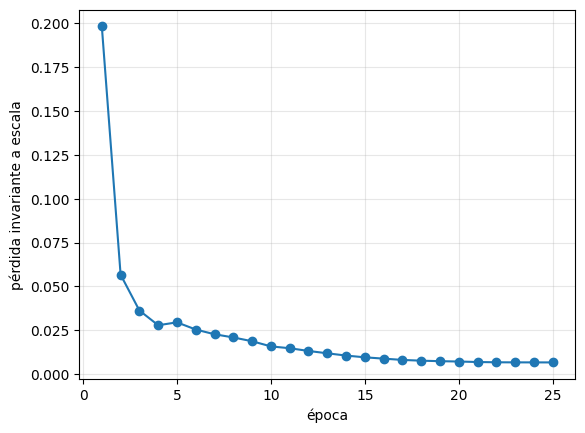

In [ ]:
historial = []
for epoca in range(EPOCAS):
    red.train()
    orden = torch.randperm(len(ell_entren))
    total = 0.0
    for k in range(len(ell_entren) // LOTE):
        idx = orden[k * LOTE:(k + 1) * LOTE]
        ell = ell_entren[idx].to(dispositivo)
        z = z_entren[idx].to(dispositivo)
        if torch.rand(1) < 0.5: # volteo horizontal como aumento de datos
            ell, z = ell.flip(-1), z.flip(-1)

        with torch.autocast(device_type="cuda", enabled=dispositivo == "cuda"):
            log_z_hat = h(ell)
        L = perdida(log_z_hat.float(), z)

        optimizador.zero_grad()
        escalador.scale(L).backward()
        escalador.step(optimizador)
        escalador.update()
        planificador.step()
        total += L.item()

    historial.append(total / (len(ell_entren) // LOTE))
    print(f"época {epoca + 1:2d}   pérdida {historial[-1]:.4f}")

plt.plot(range(1, EPOCAS + 1), historial, marker="o")
plt.xlabel("época"); plt.ylabel("pérdida invariante a escala"); plt.grid(alpha=0.3)

**5. Evaluación**

Mismas métricas y misma línea base que en el notebook CNN

In [ ]:
def metricas(z_hat, z):
    valido = z > 0.1
    z_hat, z = z_hat[valido], z[valido]
    abs_rel = (torch.abs(z_hat - z) / z).mean().item()
    delta1 = (torch.maximum(z_hat / z, z / z_hat) < 1.25).float().mean().item()
    rmse = torch.sqrt(((z_hat - z) ** 2).mean()).item()
    return abs_rel, delta1, rmse

def alinear(z_hat, z):
    valido = z > 0.1s
    return z_hat * torch.median(z[valido]) / torch.median(z_hat[valido])

red.eval()
with torch.no_grad():
    z_hat_prueba = torch.cat([torch.exp(h(ell_prueba[i:i + 32].to(dispositivo))).float().cpu()
                              for i in range(0, len(ell_prueba), 32)])

base = torch.full_like(z_prueba, z_entren[z_entren > 0.1].mean().item())

resultados = {
    "línea base (media)": metricas(base, z_prueba),
    "DINOv2 + DPT, métrica": metricas(z_hat_prueba, z_prueba),
    "DINOv2 + DPT, alineada": metricas(torch.stack([alinear(a, b) for a, b in zip(z_hat_prueba, z_prueba)]), z_prueba),
}
print(f"{'':<26}{'AbsRel':>8}{'δ1':>8}{'RMSE (m)':>10}")
for nombre, (abs_rel, delta1, rmse) in resultados.items():
    print(f"{nombre:<26}{abs_rel:>8.3f}{delta1:>8.3f}{rmse:>10.3f}")

                            AbsRel      δ1  RMSE (m)
línea base (media)           0.410   0.370     1.342
DINOv2 + DPT, métrica        0.117   0.874     0.502
DINOv2 + DPT, alineada       0.100   0.902     0.457


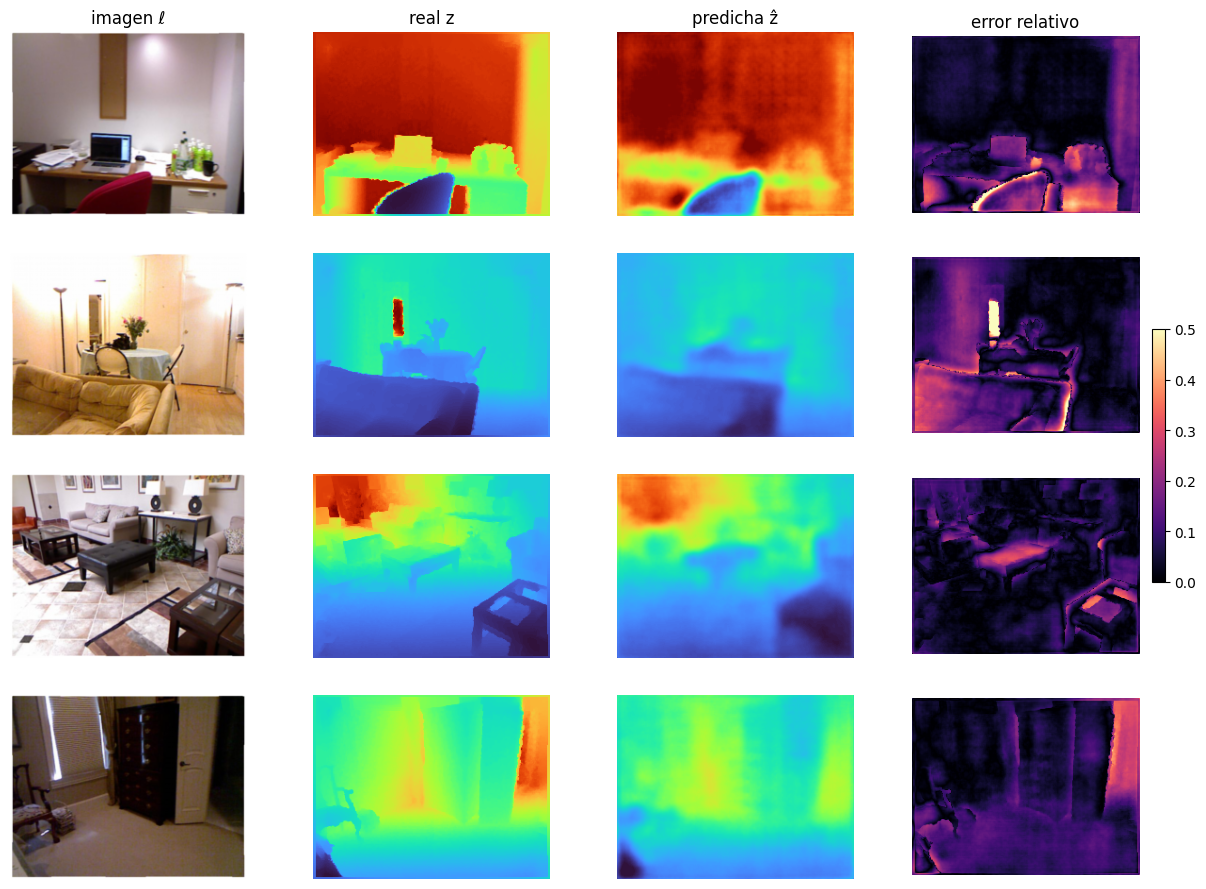

In [ ]:
fig, ax = plt.subplots(4, 4, figsize=(15, 11))
for fila, i in enumerate([3, 40, 90, 160]):
    z, z_hat = z_prueba[i, 0], z_hat_prueba[i, 0]
    vmin, vmax = z[z > 0.1].min(), z.max()
    ax[fila, 0].imshow(ell_prueba[i].permute(1, 2, 0))
    ax[fila, 1].imshow(z, cmap="turbo", vmin=vmin, vmax=vmax)
    ax[fila, 2].imshow(z_hat, cmap="turbo", vmin=vmin, vmax=vmax)
    im = ax[fila, 3].imshow(torch.abs(z_hat - z) / z * (z > 0.1), cmap="magma", vmin=0, vmax=0.5)
for x, titulo in zip(ax[0], ("imagen ℓ", "real z", "predicha ẑ", "error relativo")):
    x.set_title(titulo)
for x in ax.ravel():
    x.axis("off")
fig.colorbar(im, ax=ax[:, 3], fraction=0.05)

**7. con una foto propia**

Saving images (30).jpeg to images (30).jpeg


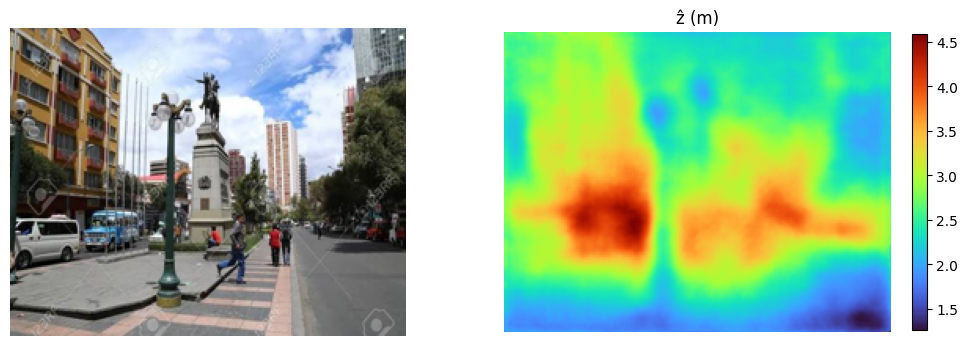

In [ ]:
from google.colab import files
from PIL import Image

nombre = list(files.upload())[0]
foto = Image.open(nombre).convert("RGB").resize((ANCHO, ALTO))
ell_propia = torch.from_numpy(np.array(foto)).permute(2, 0, 1).float()[None] / 255

with torch.no_grad():
    z_propia = torch.exp(h(ell_propia.to(dispositivo)))[0, 0].float().cpu()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(foto); ax[0].axis("off")
im = ax[1].imshow(z_propia, cmap="turbo"); ax[1].axis("off"); ax[1].set_title("ẑ (m)")
plt.colorbar(im, ax=ax[1], fraction=0.035)